# Thực nghiệm và lựa chọn mô hình
Notebook trình bày kết quả đã chạy trên hai fold phát triển. VAL trùng fold B. Tuning không dùng TEST; kết quả TEST cũ vẫn là đánh giá hồi cứu.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'appliances_core.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import appliances_core as v1
from v2 import core


In [2]:
dev = json.loads((ROOT/'out_v2/development.json').read_text(encoding='utf-8'))
display(pd.DataFrame(dev['folds']).T)

,train,evaluation,threshold,train_n,eval_n,policy_calibration_n,policy_assessment_n,policy_split_time,margin
walk_A_march,"[2016-01-11 17:00, 2016-03-01]","[2016-03-01, 2016-04-01]",1780.0,6948,4458,2226,2226,2016-03-16 12:00:00,10.816698
walk_B_april,"[2016-01-11 17:00, 2016-04-01]","[2016-04-01, 2016-04-15]",1720.0,11412,2010,1002,1002,2016-04-08 00:00:00,9.191829


In [3]:
rows = [{'cau_hinh': r['config']['name'], 'fold': r['fold'], **r['metrics']} for r in dev['rows']]
display(pd.DataFrame(rows))

,cau_hinh,fold,n,mae,rmse,bias,high_n,high_episodes,high_mae,high_rmse,high_bias,high_underprediction_rate
0,v1,walk_A_march,4458,167.984046,352.452468,-98.981671,164,32,1311.179736,1408.056448,-1310.849899,0.993902
1,persistence,walk_A_march,4458,242.548228,490.580543,0.031404,164,32,1250.731707,1401.431759,-680.121951,0.756098
2,ridge,walk_A_march,4458,199.415342,341.334825,0.251652,164,32,1106.949748,1221.869489,-1096.690334,0.975610
3,hgb_l2,walk_A_march,4458,192.502137,336.207957,29.944324,164,32,980.355514,1103.218642,-975.631383,0.975610
4,xgb_l1,walk_A_march,4458,166.428576,343.562784,-88.527860,164,32,1275.823303,1371.846709,-1275.823303,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
117,tune_20,walk_B_april,2010,211.716512,365.333324,74.010038,110,15,744.776623,933.898888,-713.552463,0.918182
118,tune_21,walk_B_april,2010,214.347428,375.030667,76.673722,110,15,692.616571,885.474735,-661.620555,0.881818
119,tune_22,walk_B_april,2010,176.524524,337.989019,-11.321381,110,15,914.849726,1089.635407,-909.014235,0.954545
120,tune_23,walk_B_april,2010,160.359295,325.017294,-36.005231,110,15,922.153368,1101.723485,-907.830034,0.936364


## Quy tắc chốt
Chấp nhận phần dự báo mới khi MAE nhóm cao giảm ít nhất 5% và MAE toàn bộ tăng không quá 3% trên cả hai fold. Chính sách cảnh báo được hiệu chỉnh trên nửa đầu mỗi giai đoạn, đánh giá ở nửa sau có purge. Giữ chính sách v1 là phương án dự phòng, không phải bằng chứng đã cải thiện cảnh báo.

,cau_hinh,dat_tieu_chi,mae_trung_binh,ty_le_mae_nhom_cao
0,v1,False,164.993084,1.000000
1,persistence,False,230.525358,0.978223
2,ridge,False,198.162835,0.840851
3,hgb_l2,False,187.063665,0.767154
4,xgb_l1,False,162.651275,0.966475
...,...,...,...,...
56,tune_20,False,216.916222,0.611465
57,tune_21,False,221.528258,0.565887
58,tune_22,False,182.896657,0.740077
59,tune_23,False,167.162264,0.767911


{'name': 'multi_hgb_l1_F_w4',
 'method': 'hgb_l1',
 'features': 'F',
 'target': 'multi',
 'weight': 4,
 'params': {},
 'stage': 'rise_weight'}

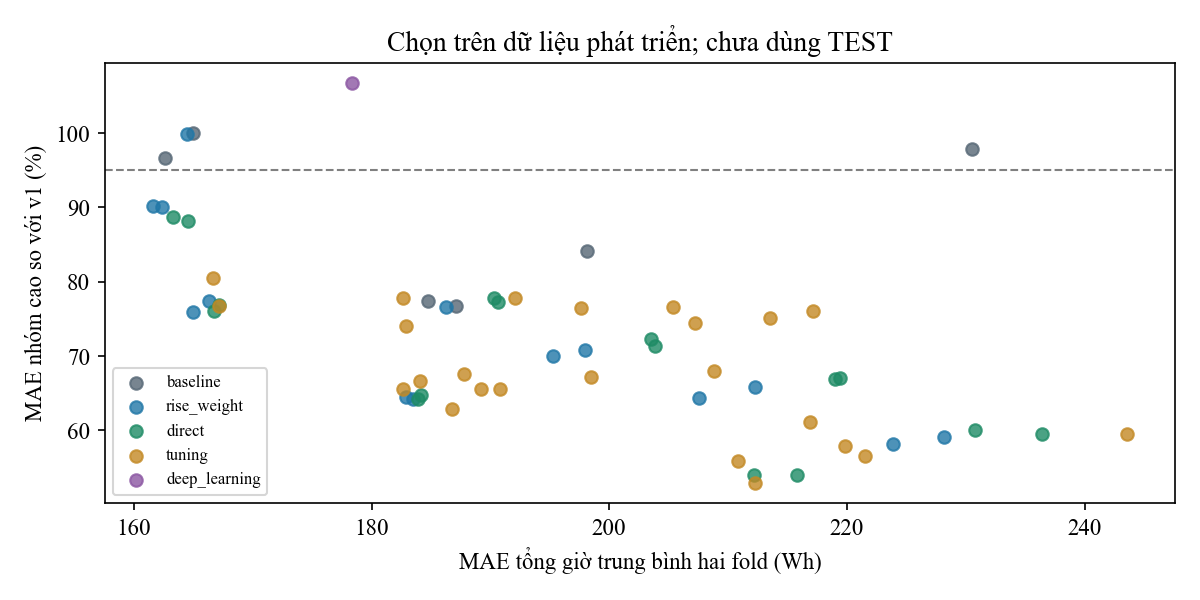

In [4]:
display(pd.DataFrame([{'cau_hinh': r['config']['name'], 'dat_tieu_chi': r['point_gate_passed'], 'mae_trung_binh': r['mean_mae'], 'ty_le_mae_nhom_cao': r['mean_relative_high_mae']} for r in dev['ranking']]))
display(dev['selection']['selected_point'])
display(Image(filename=str(ROOT/'out_v2/figures/f_v2_development.png')))